In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv('/content/Mall_Customers.csv')

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nFinal dataset shape:", df.shape)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows:
0

Final dataset shape: (200, 5)


In [5]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print(X_scaled[:5])

Feature scaling completed!
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


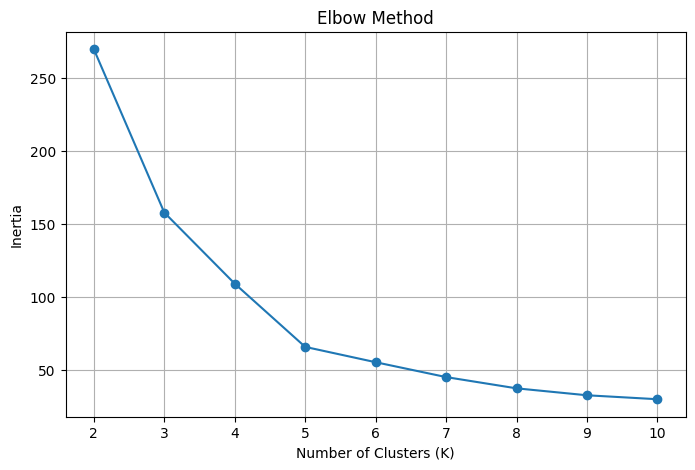

In [7]:
inertia = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)

plt.show()

K = 2 Silhouette Score = 0.3213
K = 3 Silhouette Score = 0.4666
K = 4 Silhouette Score = 0.4939
K = 5 Silhouette Score = 0.5547
K = 6 Silhouette Score = 0.5399
K = 7 Silhouette Score = 0.5281
K = 8 Silhouette Score = 0.4567
K = 9 Silhouette Score = 0.4571
K = 10 Silhouette Score = 0.4362


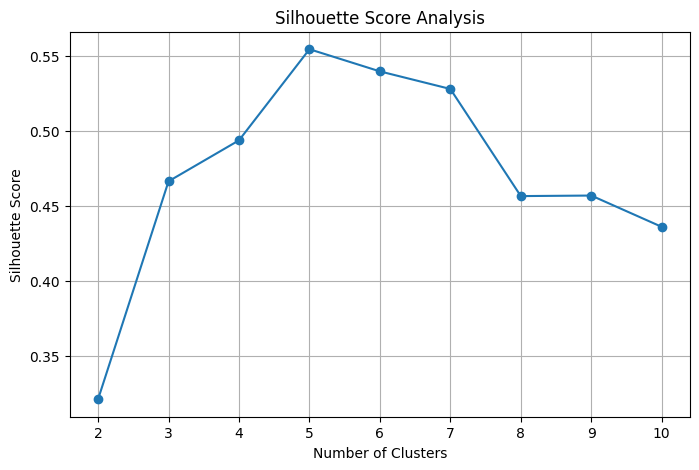

Best K according to Silhouette Score: 5


In [8]:
scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    scores.append(score)

    print("K =", k, "Silhouette Score =", round(score, 4))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), scores, marker='o')

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.show()

best_k = range(2, 11)[np.argmax(scores)]

print("Best K according to Silhouette Score:", best_k)

In [9]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=50,
    max_iter=300
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nCluster counts:")
print(df['Cluster'].value_counts().sort_index())

print("\nCluster analysis:")
print(df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2))

K-Means clustering completed!

Cluster counts:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster analysis:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91


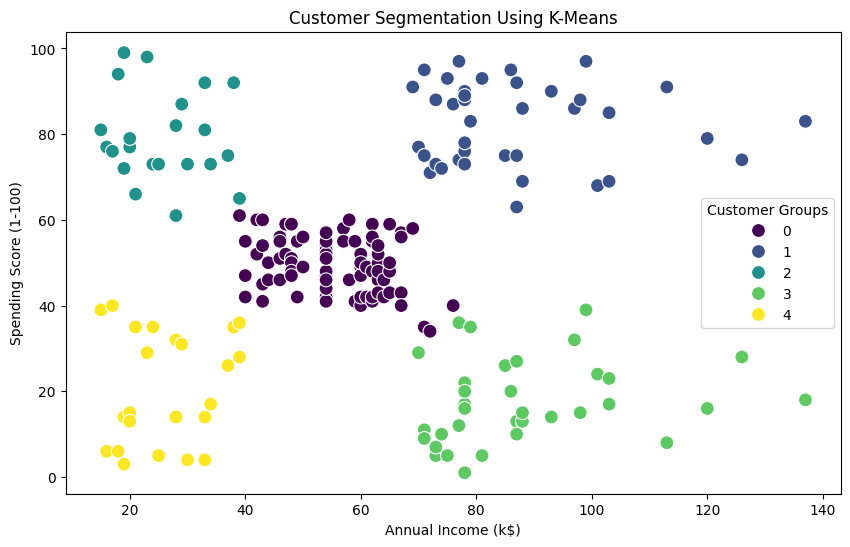

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Groups")

plt.show()

In [11]:
import time

results = []

for n in [10, 20, 50]:

    start = time.time()

    model = KMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=n,
        max_iter=300
    )

    labels = model.fit_predict(X_scaled)

    end = time.time()

    results.append({
        'n_init': n,
        'Inertia': model.inertia_,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Execution Time (seconds)': round(end-start, 5)
    })

comparison = pd.DataFrame(results)

display(comparison)

,n_init,Inertia,Silhouette Score,Execution Time (seconds)
0,10,65.568408,0.554657,0.02108
1,20,65.568408,0.554657,0.03015
2,50,65.568408,0.554657,0.07068


In [12]:
df.to_csv('Customer_Segmentation_Results.csv', index=False)

print("Final results saved successfully!")

Final results saved successfully!
